# SLU05 - Covariance and correlation: Exercise notebook

In [49]:
import pandas as pd
import numpy as np
import math
import utils
import seaborn as sns
import hashlib
from matplotlib import pyplot as plt
import utils

def _hash(s):
    return hashlib.blake2b(bytes(str(s), encoding='utf8'), digest_size=5).hexdigest()

In this notebook, you will practice the following:

- Covariance 
- Pearson correlation
- Spearman correlation
- Correlation matrix
- Spurious correlations

## Exercise 1 - Covariance and correlation with Pandas

In this exercise, you will calculate covariance and correlation on a sample dataset.

We're going to use a [dataset of car fuel consumption](https://www.kaggle.com/datasets/anderas/car-consume) for this exercise. Let's begin by taking a quick look at the dataset:

In [50]:
carride = pd.read_csv('data/carride2.csv')
carride.head()

,distance,consumption,speed,temp_outside
0,28.0,5.0,26,12.0
1,12.0,42.0,30,13.0
2,112.0,55.0,38,15.0
3,129.0,39.0,36,14.0
4,185.0,45.0,46,15.0


### Exercise 1.1 - Are speed and consumption related?

We'll begin by checking if the speed of the cars is related to the fuel consumption.

Edit the function below so that it returns the covariance, Pearson correlation, and Spearman correlation between speed and consumption.

In [51]:
def check_if_related(consumption, speed):
    """ Calculates covariance and correlations between the given variables.

    Parameters:
        consumption, speed (pd.Series): variable between which to calculate the covariance and correlations

    Returns:
        covariance (float): covariance between the given variables
        pearson_corr (float): Pearson correlation between the given variables
        spearman_corr (float): Spearman correlation between the given variables
    """
    # YOUR CODE HERE
    covariance = consumption.cov(speed)
    pearson_corr = consumption.corr(speed)
    spearman_corr = consumption.corr(speed, method='spearman')
    return covariance, pearson_corr, spearman_corr

In [52]:
consumption, speed = utils.get_distance_speed()
cov, p_corr, s_corr = check_if_related(consumption, speed)
np.testing.assert_almost_equal(cov, -25.061536002557343, decimal=3, err_msg="The covariance seems to be wrong.")
np.testing.assert_almost_equal(p_corr, -0.10365751316032523, decimal=3, err_msg="The Pearson correlation seems to be wrong.")
np.testing.assert_almost_equal(s_corr, -0.11331148715392869, decimal=3, err_msg="The Spearman correlation seems to be wrong.")
print(f"Well done! Everything seems to be in order! Approximated values:\nCovariance = "
    f"{round(check_if_related(consumption, speed)[0],2)}\n"
    "Pearson correlation  = "
    f"{round(check_if_related(consumption, speed)[1],2)}\n"
    "Spearman correlation = "
    f"{round(check_if_related(consumption, speed)[2],2)}\n"
    "The results show that the correlation is not significant.")

Well done! Everything seems to be in order! Approximated values:
Covariance = -25.06
Pearson correlation  = -0.1
Spearman correlation = -0.11
The results show that the correlation is not significant.


### Exercise 1.2 - Changing units

Now for a simple multiple choice exercise. The distance unit in the dataset is meter. Let's assume we want to know the distances in feet.

We know that 1 meter = 3.28 feet, meaning that the unitary distance represented in the unit 'feet' is larger than the unitary distance represented in the dataset unit, meter.

If we extract the covariance and Pearson/Spearman correlations again, but this time in feet, which of the following statements is true?

- A. The covariance, Pearson correlation and Spearman correlation will decrease.
- B. The covariance will increase, but the Pearson correlation and Spearman correlation will decrease.
- C. They all (covariance, Pearson correlation and Spearman correlation) remain the same.
- D. The covariance will increase, but Pearson correlation and Spearman correlation will remain the same.

Write the letter corresponding to your chosen answer as a text string into the variable `ex1_answer` below.

In [53]:
# ex1_answer = "Z"
# YOUR CODE HERE
ex1_answer = "D"

In [54]:
assert _hash(ex1_answer.lower()) == '838cd7f570', "Wrong choice. Remember that correlation does not depend on units."
print("Good job!")

Good job!


## Exercise 2 - Pearson experiment

The following dataset presents the heights of fathers and their sons, based on a famous Karl Pearson's experiment around 1903. The number of cases is 1078. Random noise was added to the original data, to produce heights to the nearest 0.1 inch.  
(more info: https://www.kaggle.com/datasets/abhilash04/fathersandsonheight)

In [55]:
fathers_sons_heights = pd.read_csv('data/pearson.csv')
fathers_sons_heights.head()

,Fathers,Sons
0,65.0,59.8
1,63.3,63.2
2,65.0,63.3
3,65.8,62.8
4,61.1,64.3


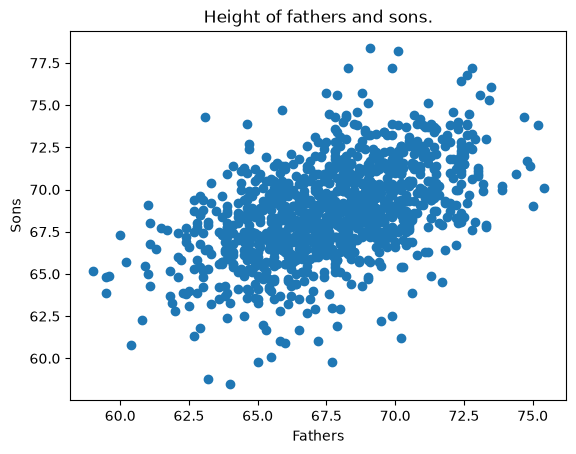

In [56]:
plt.scatter(fathers_sons_heights['Fathers'],fathers_sons_heights['Sons'])
plt.xlabel('Fathers')
plt.ylabel('Sons')
plt.title('Height of fathers and sons.');

### Exercise 2.1 - What can you read from the plot?
What can we infer from the scatter plot above concerning the height variable?

    A. There is no correlation between Father and son.

    B. There is a negative correlation visible.

    C. There is a positive correlation visible.

    D. Nothing can be inferred from just the graph.
    
Write the letter corresponding to your chosen answer as a text string into the variable `ex2_answer` below.

In [57]:
# ex2_answer = "Z"
# YOUR CODE HERE
ex2_answer = "C"

In [58]:
assert _hash(ex2_answer.lower()) == '2add4c06d4', "Not correct. Remember that the correlation is not affected by the unit choice."
print("Nice!")

Nice!


### Exercise 2.2 - The outliers
Now let's look at another data set fathers and sons heights. We can spot some really weird heights or so called outliers. This could be the tallest man ever, or giants really existed!

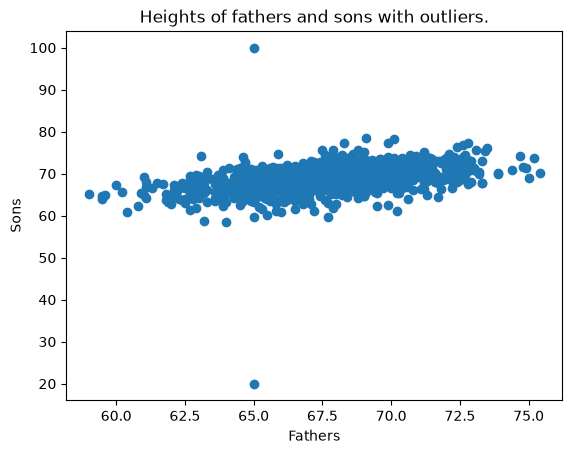

In [59]:
outliers_fathers_sons = pd.read_csv('data/outlier_data.csv')
plt.scatter(outliers_fathers_sons['Fathers'],outliers_fathers_sons['Sons'])
plt.xlabel('Fathers')
plt.ylabel('Sons')
plt.title('Heights of fathers and sons with outliers.');

Calculate the Pearson and Spearman correlations between the fathers' and sons' heights for this (`outlier_data`) and the previous (`fathers_sons_heights`) data set. What do results do you expect?

In [60]:
# pearson_corr_normal, spearman_corr_normal = 
# pearson_corr_outlier, spearman_corr_outlier = 

# YOUR CODE HERE
pearson_corr_normal = fathers_sons_heights['Fathers'].corr(fathers_sons_heights['Sons'])
spearman_corr_normal = fathers_sons_heights['Fathers'].corr(fathers_sons_heights['Sons'], method='spearman')

pearson_corr_outlier = outliers_fathers_sons['Fathers'].corr(outliers_fathers_sons['Sons'])
spearman_corr_outlier = outliers_fathers_sons['Fathers'].corr(outliers_fathers_sons['Sons'], method='spearman')

So far, so good!
Pearson without outlier : 0.5011626808075913
Pearson with outlier    : 0.42909473852495256
Spearman without outlier: 0.5056466119232446
Spearman with outlier   : 0.5036232636411857


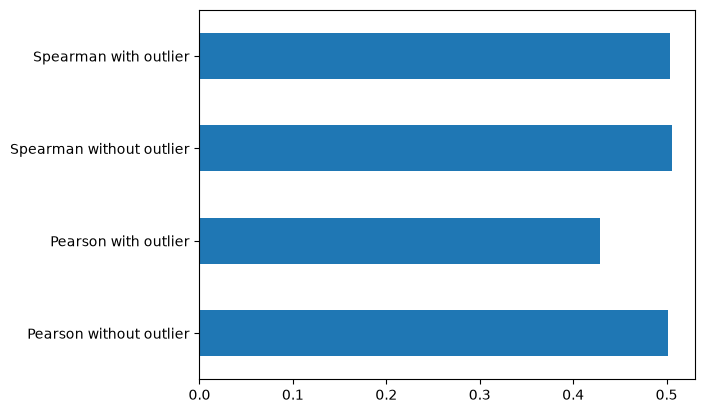

In [61]:
np.testing.assert_almost_equal(pearson_corr_normal - pearson_corr_outlier, 0.07206794228263841, decimal=4,
                err_msg="The Pearson correlations seems to be off. You should see some change between the two datasets.")
np.testing.assert_almost_equal(spearman_corr_normal - spearman_corr_outlier, 0.0020233482820588566, decimal=4,
                err_msg="The Spearman correlation seems to be off. You should see almost no change between the two datasets.")
print("So far, so good!")
# quick plot to see what happens
utils.plot_correlation_bargraph(pearson_corr_normal, pearson_corr_outlier,
                          spearman_corr_normal, spearman_corr_outlier)

### Exercise 2.3 - What to do when you have outliers?

So, unsurprisingly, the higher the dads are, the higher the sons: a positive correlation. But, as you can see, having outliers may hugely affect your analysis. Then, when dealing with a dataset with outliers, which correlation methodology should you use?

    A. Pearson.

    B. Spearman.

Write the letter corresponding to your chosen answer as a text string into the variable `ex3_answer` below.

In [62]:
# ex3_answer = "Z"
# YOUR CODE HERE
ex3_answer = "B"

In [63]:
assert _hash(ex3_answer.lower()) == '9350f68d6b', "Not correct. Look at the changes in the correlations in the bar graphs."
print("Nice! Now you can avoid the data disruption caused by the longest or "
      "shortest man ever alive!")

Nice! Now you can avoid the data disruption caused by the longest or shortest man ever alive!


## Exercise 3 - Interest in health issues 

This health search dataset includes an index of volumes of searches for various common medical topics in the United States. The data covers the period 2004 for all the US counties. source: https://www.searching-for-health.com/

In [64]:
health = pd.read_csv('data/health_issue.csv')
health.head()

,cancer,cardiovascular,stroke,depression,rehab,vaccine,diarrhea,obesity,diabetes
0,44,6,17,39,21,31,14,29,38
1,47,6,13,38,16,33,12,27,32
2,48,3,16,50,12,37,24,31,37
3,44,14,14,37,19,49,14,29,31
4,52,7,16,41,23,36,14,30,37


Explore the dataset using the tools you learned in this SLU, then answer the questions in the cell below:

- you can use `display()` to force it to pretty print.
- use the heatmap of the correlation matrix that we used in the learning notebooks.
- you may want to import something to help with the visualization.
- you can either paste the answers or use a purely programmatic solution.

,cancer,cardiovascular,stroke,depression,rehab,vaccine,diarrhea,obesity,diabetes
cancer,1.000000,0.039434,0.224162,0.285365,-0.032841,0.093358,0.059052,0.069438,0.170824
cardiovascular,0.039434,1.000000,0.256867,0.021798,-0.162104,-0.017913,0.500353,-0.030771,0.317098
stroke,0.224162,0.256867,1.000000,0.337162,-0.146270,0.053352,0.203472,-0.122986,0.485562
depression,0.285365,0.021798,0.337162,1.000000,0.124677,0.214679,0.069900,0.086812,0.334501
rehab,-0.032841,-0.162104,-0.146270,0.124677,1.000000,0.038846,-0.032934,0.152608,0.020924
vaccine,0.093358,-0.017913,0.053352,0.214679,0.038846,1.000000,0.072661,0.043121,-0.072745
diarrhea,0.059052,0.500353,0.203472,0.069900,-0.032934,0.072661,1.000000,-0.065039,0.110569
obesity,0.069438,-0.030771,-0.122986,0.086812,0.152608,0.043121,-0.065039,1.000000,0.066707
diabetes,0.170824,0.317098,0.485562,0.334501,0.020924,-0.072745,0.110569,0.066707,1.000000


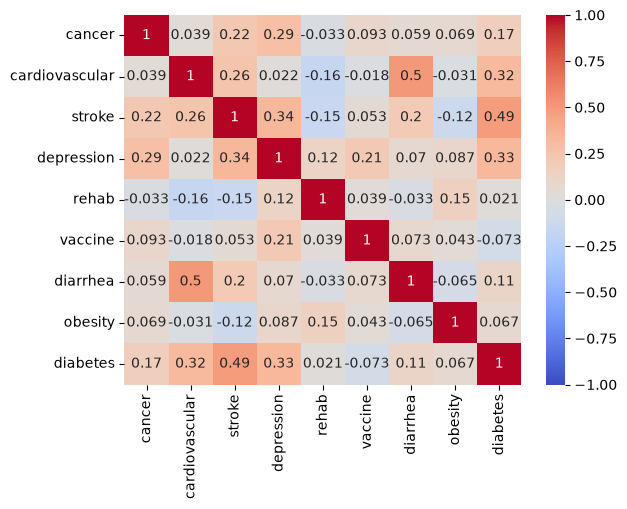

In [65]:
# explore the dataset

# YOUR CODE HERE
corr = health.corr(numeric_only=True)
display(corr)
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

In [66]:
# Complete the following questions

# Q1: What is the pair of health issues with the most negative Pearson
#   correlation?
# (pass the answer as a list, and remember, you can just type it in, no
#   fancy Pandas needed)
# health_pair_with_lowest_pearson_corr = ...
# YOUR CODE HERE
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
health_pair_with_lowest_pearson_corr = list(pairs.idxmin())

# # Q2: What is the health issue with the most negative Pearson
#   correlation with Obesity?
# health_rank_pearson_corr_with_obesity = ...
# YOUR CODE HERE
health_rank_pearson_corr_with_obesity = corr['obesity'].drop('obesity').idxmin()

# Q3: What is the Spearman correlation between vaccine and stroke?
# spearman_corr_between_vaccine_and_stroke = ...
# YOUR CODE HERE
spearman_corr_between_vaccine_and_stroke = health['vaccine'].corr(health['stroke'], method='spearman')

# Q4: Observe the top Pearson correlation pairs, and then look at the
#   general correlation matrix.
# Which health issue seems to be the most correlated to other health
#   issues making it a possible confounding variable?
# possible_confounding_variable =
# YOUR CODE HERE
possible_confounding_variable = 'diabetes'

In [67]:
assert _hash(sorted([h.lower() for h in health_pair_with_lowest_pearson_corr])) == '506ae2bc48',\
"That is not the pair with the lowest Pearson correlation."
assert _hash(health_rank_pearson_corr_with_obesity.lower()) == '2def1fe0b7', "That is not it, look again."
np.testing.assert_almost_equal(spearman_corr_between_vaccine_and_stroke, 0.187897, decimal=3,
                    err_msg="Wrong spearman correlation value between vaccine and stroke.")
assert _hash(possible_confounding_variable.lower()) == '22037c48a8', "Not correct, check again."
print("You got it!")

You got it!


## Exercise 4 - Lots of stocks
You were hired by a hedge fund, because money. 

On the first day, your boss, Greedy McRiskyface asked you to select one stock pair so that he can short one and long the other.

Note: If an investor wants to short (sell) one stock and long (buy) another it means they expects the prices to move in **oposite directions!** This aspect will help you understand which correlation extreme you're expected to find.

If you select the best possible pair (use Pearson) you get a raise!

The answer should be (1) the two stocks, as a list and (2) their Pearson correlation, as a float.

It is very important that you restart the kernel everytime you run this exercise, otherwise the asserts might not pass although your solution is correct.

In [68]:
stock_data = utils.get_stocks_data_2()
stock_data.head()

,LJA,VDG,BBM,LNK,QEX,MTD,RLL,XBZ,UVL,WGS,...,XTE,MCF,MEB,RGT,NFL,DPY,AOV,IOD,IMM,CTA
2018-01-01,9.803844,1.725104,14.254243,7.232871,13.087118,3.184990,0.610644,5.957917,3.496983,12.626111,...,13.658227,8.736232,13.012602,7.835670,14.743409,14.348503,1.876495,7.587784,3.619850,14.569473
2018-01-02,2.347938,8.579079,9.492765,3.418111,2.120899,7.097890,4.204465,1.063179,2.957755,2.805289,...,4.229851,14.691193,14.605433,8.399848,13.240564,3.005584,12.908135,10.041376,7.484980,8.193455
2018-01-03,11.611426,14.672306,2.551748,14.501356,14.963244,14.137359,14.962111,0.893354,0.484938,13.362902,...,11.902079,5.323784,13.023309,7.846701,2.536548,10.799837,10.929938,14.830502,7.880684,0.832521
2018-01-04,10.833609,11.033981,13.094109,1.736075,5.930236,7.898302,12.051334,3.343707,6.277371,7.971141,...,12.517399,10.864442,13.207647,6.230960,11.700194,1.363189,5.378140,0.941203,5.472675,4.730645
2018-01-05,13.502135,8.240586,11.100002,13.256499,14.005095,4.328847,6.838013,14.567100,13.741203,1.229671,...,9.522394,2.364496,6.802103,5.453134,14.089296,8.520676,10.873779,1.206582,8.899308,14.092952


In [69]:
# selected_stock_pair = ...
# selected_stock_pair_pearson_corr = ...
# YOUR CODE HERE
corr_stocks = stock_data.corr()
pairs = corr_stocks.where(np.triu(np.ones(corr_stocks.shape, dtype=bool), k=1)).stack()
selected_stock_pair = list(pairs.idxmin())
selected_stock_pair_pearson_corr = float(pairs.min())

In [70]:
assert isinstance(selected_stock_pair, list), "The variable should be a list."
assert len(selected_stock_pair) == 2, "There should be two stocks in the list."
assert _hash(sorted(selected_stock_pair))=='56085de6e5', 'The selected stock pair is not correct.'
np.testing.assert_almost_equal(selected_stock_pair_pearson_corr, -0.4694947400556539, decimal=3),
err_msg="The Pearson correlation value is not correct."
utils.dirty_little_secret()


    Ok, first the good news: You got a raise on your first day at the job!!! :)

    And now, the "not so good"...
    we tricked you, and it was unfair of us.

    The reality is that this stock dataset was 100% RANDOM NUMBERS.

    The thing to remember is: if you use correlation without knowing the data, you are always going to find "something".
    A lot of bad data science comes from over trusting the tools without knowing the data.

    If you have enough data and dig into it using correlation you will ALWAYS find something
    ... even if there is nothing to be found.

    Correlation does not equal causality.
    And sometimes, it just means you found a signal where there was only noise.

    Now go on to the next SLU, and remember the day you modeled random numbers and found good stocks to buy/sell :)
    
